# Design `unit_price_by_station_palo_alto.csv`

Regenerate per-station **`median_unit_price_per_kwh`** with small random variation around each station's current median (or the paid-station cluster median when the value is `0`).

**Range rule:** `PRICE_RANGE = 0.05` → new price ∈ `[anchor − 0.05, anchor + 0.05]` (±5 **cents** per kWh). Adjust the constant below if you meant a different scale.

Output overwrites `unit_price_by_station_palo_alto.csv` in this folder.

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INPUT_CSV = "before_unit_price_by_station_palo_alto.csv"
OUTPUT_CSV = "unit_price_by_station_palo_alto.csv"

# ±5 cents per kWh around each station's anchor median
PRICE_RANGE = 0.05
RANDOM_SEED = 42

In [4]:
df = pd.read_csv(INPUT_CSV)
df

,Unnamed: 0,Station Name,median_unit_price_per_kwh,session_count,price_tier
0,38,PALO ALTO CA / SHERMAN 8,0.302662,2,1.0
1,29,PALO ALTO CA / SHERMAN 14,0.230350,2,1.0
2,39,PALO ALTO CA / SHERMAN 9,0.230330,1,1.0
3,28,PALO ALTO CA / SHERMAN 11,0.230267,1,1.0
4,31,PALO ALTO CA / SHERMAN 17,0.230224,1,1.0
5,37,PALO ALTO CA / SHERMAN 7,0.230168,4,1.0
6,36,PALO ALTO CA / SHERMAN 6,0.230133,3,1.0
7,30,PALO ALTO CA / SHERMAN 15,0.230116,1,1.0
8,33,PALO ALTO CA / SHERMAN 3,0.230109,8,1.0
9,10,PALO ALTO CA / CAMBRIDGE #4,0.230090,3428,1.0


## 1. Load current file

In [5]:
original_median = df["median_unit_price_per_kwh"].copy()

paid = original_median[original_median > 0]
cluster_median = float(paid.median()) if len(paid) else 0.23

print(f"Stations: {len(df)}")
print(f"Paid stations (price > 0): {len(paid)}")
print(f"Free / zero stations: {(original_median == 0).sum()}")
print(f"Cluster median (paid only): ${cluster_median:.4f}/kWh")
print(f"Original price range: ${original_median.min():.4f} – ${original_median.max():.4f}/kWh")

Stations: 47
Paid stations (price > 0): 29
Free / zero stations: 18
Cluster median (paid only): $0.2301/kWh
Original price range: $0.0000 – $0.3027/kWh


## 2. Randomize within ±`PRICE_RANGE` of anchor

In [9]:
rng = np.random.default_rng(RANDOM_SEED)

# Anchor: own median when > 0, else cluster median (replaces former free stations)
anchor = original_median.where(original_median > 0, cluster_median)

low = np.maximum(0.0, anchor - PRICE_RANGE)
high = anchor + PRICE_RANGE

random_prices = rng.uniform(low, high)

df["median_unit_price_per_kwh"] = np.round(random_prices, 6)

# Simple tier: 0 = budget (bottom third), 1 = mid, 2 = premium (top third) among paid-like prices
prices = df["median_unit_price_per_kwh"]
q33, q66 = prices.quantile([1 / 3, 2 / 3])
df["price_tier"] = np.select(
    [prices <= q33, prices <= q66],
    [0.0, 1.0],
    default=2.0,
)

df[["Station Name", "median_unit_price_per_kwh", "session_count", "price_tier"]]

,Station Name,median_unit_price_per_kwh,session_count,price_tier
0,PALO ALTO CA / SHERMAN 8,0.330058,2,2.0
1,PALO ALTO CA / SHERMAN 14,0.224238,2,1.0
2,PALO ALTO CA / SHERMAN 9,0.266190,1,2.0
3,PALO ALTO CA / SHERMAN 11,0.250004,1,1.0
4,PALO ALTO CA / SHERMAN 17,0.189642,1,0.0
5,PALO ALTO CA / SHERMAN 7,0.277730,4,2.0
6,PALO ALTO CA / SHERMAN 6,0.256247,3,2.0
7,PALO ALTO CA / SHERMAN 15,0.258722,1,2.0
8,PALO ALTO CA / SHERMAN 3,0.192920,8,0.0
9,PALO ALTO CA / CAMBRIDGE #4,0.225129,3428,1.0


In [7]:
delta = (df["median_unit_price_per_kwh"] - anchor).abs()
print(f"Max |new − anchor|: ${delta.max():.4f}/kWh (cap = {PRICE_RANGE})")
print(f"New price range: ${df['median_unit_price_per_kwh'].min():.4f} – ${df['median_unit_price_per_kwh'].max():.4f}/kWh")
print("Price tier counts:")
print(df["price_tier"].value_counts().sort_index())

Max |new − anchor|: $0.0476/kWh (cap = 0.05)
New price range: $0.0784 – $0.3301/kWh
Price tier counts:
price_tier
0.0    16
1.0    15
2.0    16
Name: count, dtype: int64


## 3. Visual check

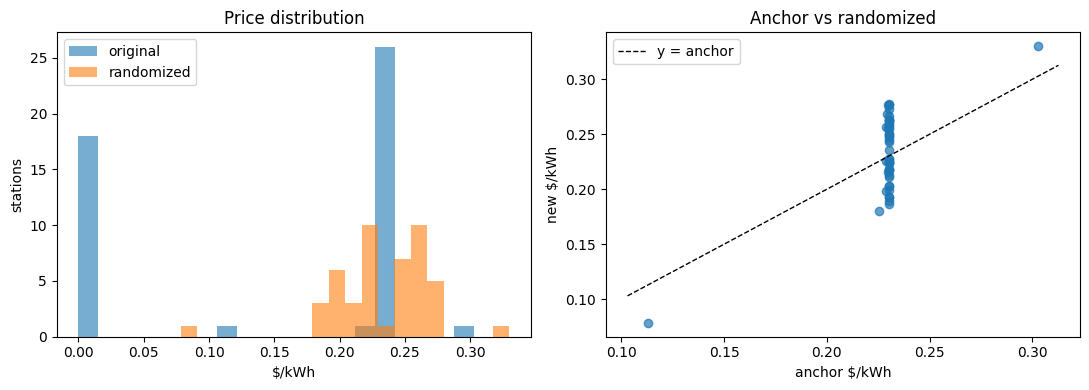

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(original_median, bins=20, alpha=0.6, label="original")
axes[0].hist(df["median_unit_price_per_kwh"], bins=20, alpha=0.6, label="randomized")
axes[0].set_xlabel("$/kWh")
axes[0].set_ylabel("stations")
axes[0].set_title("Price distribution")
axes[0].legend()

axes[1].scatter(anchor, df["median_unit_price_per_kwh"], alpha=0.7)
lims = [anchor.min() - 0.01, anchor.max() + 0.01]
axes[1].plot(lims, lims, "k--", linewidth=1, label="y = anchor")
axes[1].set_xlabel("anchor $/kWh")
axes[1].set_ylabel("new $/kWh")
axes[1].set_title("Anchor vs randomized")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Save (replaces CSV)

In [11]:
df.to_csv(OUTPUT_CSV, index=True)
print(f"Wrote {OUTPUT_CSV} ({len(df)} rows)")

Wrote unit_price_by_station_palo_alto.csv (47 rows)
